<!--

    Gaia Data Processing and Analysis Consortium (DPAC) 
    Co-ordination Unit 9 Work Package 930
    
    (c) 2005-2025 Gaia DPAC
    
    This program is free software: you can redistribute it and/or modify
    it under the terms of the GNU General Public License as published by
    the Free Software Foundation, either version 3 of the License, or
    (at your option) any later version.

    This program is distributed in the hope that it will be useful,
    but WITHOUT ANY WARRANTY; without even the implied warranty of
    MERCHANTABILITY or FITNESS FOR A PARTICULAR PURPOSE.  See the
    GNU General Public License for more details.

    You should have received a copy of the GNU General Public License
    along with this program.  If not, see <https://www.gnu.org/licenses/>.
    -->

This simple example shows how to use the PySpark SQL API to execute a simple query on the main source catalogue and plot the results.

Notes:

* The cell containing the query below finishes instantly since it merely defines a "transformation" (in the language of Spark) without actually actioning it. It is only when something is done with the data selected by this transform (i.e. it is explicitly actioned as in the following cell) that execution occurs
* Visualisation takes advantage of HEALPix pixelisation encoded in the Gaia source IDs, and the healpy Python package in conjunction with matplotlib
* Links are provided in the final cell to the documentation for the packages used, along with other relevant resources.



In [1]:
# Import the spark config
from astroflow_spark_gaia import spark
import math

# set the resolution of the counts
healpix_level = 6
# HEALPix level : no. of pixels
# 4 : 3072
# 5 : 12288
# 6 : 49152 ~ 1 square degree pixels
# 7 : 196608

# Note: the most significant four-byte word of the 8-byte Gaia source ID contains a HEALPix level 12 index from bit 35 and higher
nside = int(math.pow(2, healpix_level))
powers_of_2 = 35 + (12 - healpix_level)*2
divisor = int(math.pow(2, powers_of_2))

# make the query: integer division via the PySpark SQL FLOOR function is used to create bin UIDs by which to group the count
df = spark.sql("SELECT FLOOR(source_id / %d"%(divisor) + ") AS hpx_id, COUNT(*) AS n FROM gaia_source GROUP BY hpx_id")

Beginning the initilization of a spark cluster with 10 pods, 5 cores/pod and 7g mem/pod


25/05/29 13:24:22 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Completed initialisation
Setting up SparkSQL
Setting up dataset Gaia DR3 with 2 databases gaiadr3, gaiaedr3
A spark cluster has been sucessfully set up, you can interact with it via the "spark" object


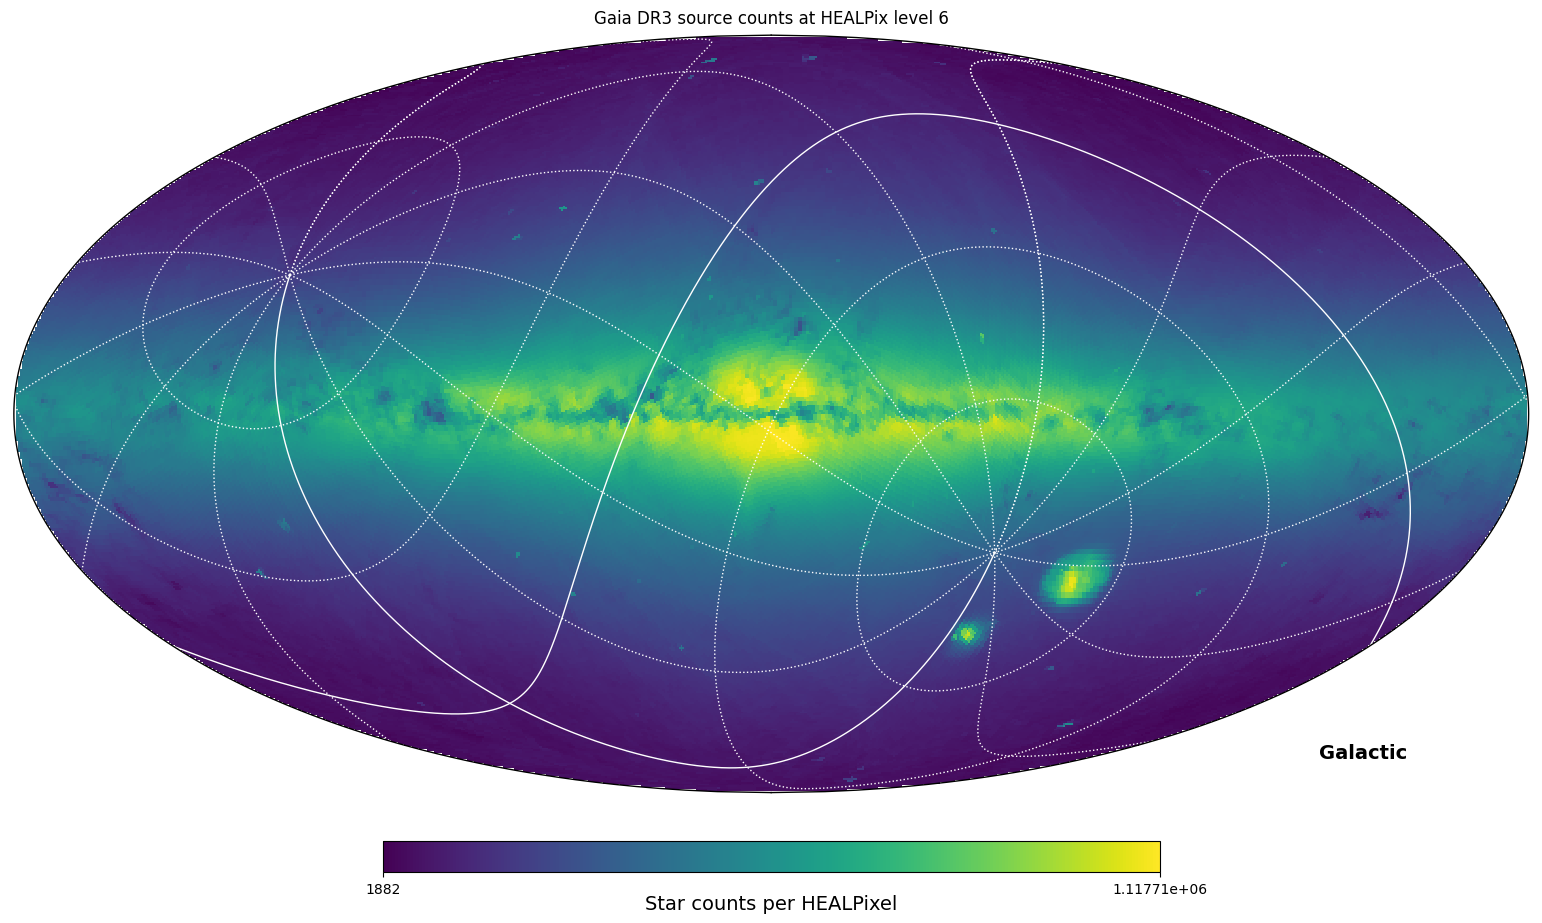

In [2]:
# plot up the sky counts
import numpy as np
import healpy as hp
import matplotlib.pyplot as plot

# set a figure to use along with a plot size (landscape, golden ratio)
plot.figure(1, figsize = (16.18, 10.0))

# healpy constants appropriate to the HEALPix indexing encoded in Gaia source IDs
npix = hp.nside2npix(nside)

# do the visualisation
array_data = np.empty(npix)
# access the underlying Spark Resilient Distributed Data object of the data frame to get the relevant data for plotting ...
for item in df.rdd.collect():  array_data[item[0]] = item[1]
# ... this is just one way of several ...

# plot the counts in Mollweide projection ...
hp.mollview(array_data, fig=1, nest=True, coord='CG', unit = 'Star counts per HEALPixel', title='Gaia DR3 source counts at HEALPix level %d'%(healpix_level), cmap='viridis', norm = 'log')
# ... with an Equatorial graticule
hp.graticule(coord='C', color='white')

* [Gaia source ID definition (for HEALPix indexing)](https://dms.cosmos.esa.int/COSMOS/doc_fetch.php?id=2779219)
* [Python package healpy](https://healpy.readthedocs.io/en/latest/index.html)
* [Python matplotlib plotting library](https://matplotlib.org)
* [Handy HEALPixel characteristics for various levels](https://lambda.gsfc.nasa.gov/toolbox/pixelcoords.html)
